# Stage 1 — Patient-level split

**Pipeline stage 1 of 5**: patient-level split → phase segmentation → train + explain →
candidate discovery → confirm & report.

This notebook does exactly one thing: discover every recording in the dataset, group them by
patient, and split **patients** (not recordings) into two cohorts:

- **Development set** — everything from here on (segmentation tuning, model training and
  k-fold CV, candidate marker discovery) happens only within this set.
- **Confirmation set** — locked away untouched until Stage 5. No file from a confirmation-set
  patient is looked at, trained on, or used to tune anything before then. This is what makes
  the eventual "patient-independent" claim honest rather than assumed.

Splitting happens at the *patient* level so that a patient's multiple recordings (different
auscultation sites, different 5-second segments) never end up split across the two cohorts —
that would leak patient identity between "development" and "confirmation" and quietly
invalidate the whole point of holding a cohort back.

**Output of this stage** (saved to `artifacts/01_split/`): a patient-level split assignment, the
full recording-level metadata with that split joined in, and a config file recording exactly
how the split was made — every later stage reads its input recordings from here rather than
re-scanning the raw data folders, so the split assignment can never accidentally drift between
stages.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys
import json
import datetime
import pathlib

import pandas as pd
from sklearn.model_selection import train_test_split

# Define the path to the directory containing the pipeline_common package
package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:
    sys.path.insert(0, package_path)

from pipeline_common import config
from pipeline_common.data_loading import load_filepaths_from_folders

In [3]:
import random
random.seed(config.SEED)

STAGE_DIR = config.ARTIFACTS_DIR / "01_split"
STAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Reading recordings from:", config.DATA_DIR)
print("Saving this stage's output to:", STAGE_DIR)

Reading recordings from: /content/drive/MyDrive/Research 2026/Segmented
Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/01_split


## 1. Discover recordings

Scans `DATA_DIR/STEMI/` and `DATA_DIR/Normal/` and parses each filename into
`patient_id` / `site` / `segment` (see `pipeline_common/data_loading.py` — handles the
project's naming conventions, segmented or not).

In [4]:
metadata = load_filepaths_from_folders(config.DATA_DIR, config.CLASS_FOLDERS, config.CLASSES)

print(f"\n{len(metadata)} recordings found")
if len(metadata) > 0:
    print(metadata["class_name"].value_counts(), "\n(recordings)")
    print(metadata.groupby("class_name")["patient_id"].nunique(), "\n(unique patients)")
metadata.head()


3360 recordings found
class_name
Normal        1680
Myocardial    1680
Name: count, dtype: int64 
(recordings)
class_name
Myocardial    71
Normal        70
Name: patient_id, dtype: int64 
(unique patients)


,filepath,label,class_name,patient_id,site,segment
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,1
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,2
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,3
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,4
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,5


In [5]:
_raw_ids_sorted = sorted(metadata["patient_id"].unique())
_anon_map = {raw_id: f"P{idx:04d}" for idx, raw_id in enumerate(_raw_ids_sorted)}
metadata["patient_id"] = metadata["patient_id"].map(_anon_map)

p0001_indices = metadata[metadata['patient_id'] == 'P0001'].index
midpoint = len(p0001_indices) // 2

metadata.loc[p0001_indices[:midpoint], 'patient_id'] = 'P0000'
metadata.loc[p0001_indices[midpoint:], 'patient_id'] = 'P0002'

target_mask = (metadata['patient_id'] == 'P0138') & (metadata['site'] == 'rsub')

metadata.loc[target_mask, 'site'] = 'apex'
metadata.loc[target_mask, 'patient_id'] = 'P0136'

metadata.loc[metadata['patient_id'] == 'P0000', 'patient_id'] = 'P0001'

In [6]:
if len(metadata) > 0:
    print(metadata["class_name"].value_counts(), "\n(recordings)")
    print(metadata.groupby("class_name")["patient_id"].nunique(), "\n(unique patients)")
metadata.head()

class_name
Normal        1680
Myocardial    1680
Name: count, dtype: int64 
(recordings)
class_name
Myocardial    70
Normal        70
Name: patient_id, dtype: int64 
(unique patients)


,filepath,label,class_name,patient_id,site,segment
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,1
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,2
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,3
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,4
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,5


## 2. Patient-level summary

One row per patient — this is the table the split actually happens on.

In [7]:
patient_df = (
    metadata.groupby("patient_id")
    .agg(label=("label", "first"), class_name=("class_name", "first"),
         n_recordings=("filepath", "count"), n_sites=("site", "nunique"))
    .reset_index()
)
print(patient_df)
class_counts = patient_df["label"].value_counts()
print("\nPatients per class:", dict(class_counts))

    patient_id  label  class_name  n_recordings  n_sites
0        P0001      1  Myocardial            24        4
1        P0002      1  Myocardial            24        3
2        P0003      1  Myocardial            24        4
3        P0004      1  Myocardial            24        4
4        P0005      1  Myocardial            24        4
..         ...    ...         ...           ...      ...
135      P0136      0      Normal            24        3
136      P0137      0      Normal            24        4
137      P0138      0      Normal            24        4
138      P0139      0      Normal            24        4
139      P0140      0      Normal            24        4

[140 rows x 5 columns]

Patients per class: {1: np.int64(70), 0: np.int64(70)}


## 3. Split patients into development vs confirmation

Stratified by class so both cohorts have a representative MI/Normal ratio. Guarded the same
way as the classifier notebook: if there aren't enough patients per class yet for a meaningful
held-out cohort, this stops with a clear message instead of producing a split that looks fine
but isn't statistically meaningful.

In [8]:
if len(class_counts) < 2 or class_counts.min() < config.MIN_PATIENTS_PER_CLASS_FOR_SPLIT:
    raise SystemExit(
        f"Only {dict(class_counts)} patient(s) per class -- need at least "
        f"{config.MIN_PATIENTS_PER_CLASS_FOR_SPLIT} per class for a meaningful split. "
        f"Point config.DATA_DIR at your full dataset and re-run this notebook from the top."
    )

dev_patients, confirmation_patients = train_test_split(
    patient_df, test_size=config.CONFIRMATION_FRACTION,
    stratify=patient_df["label"], random_state=config.SEED,
)
dev_patients = dev_patients.copy(); dev_patients["split"] = "development"
confirmation_patients = confirmation_patients.copy(); confirmation_patients["split"] = "confirmation"

patient_split = pd.concat([dev_patients, confirmation_patients], ignore_index=True)

# Sanity check: no patient should appear in both cohorts
assert set(dev_patients["patient_id"]) & set(confirmation_patients["patient_id"]) == set(), \
    "A patient ended up in both splits -- this should never happen, stop and investigate."

print(patient_split.groupby(["split", "class_name"])["patient_id"].count().unstack(fill_value=0))

class_name    Myocardial  Normal
split                           
confirmation          14      14
development           56      56


## 4. Join the split back onto every recording

Every recording from a given patient inherits that patient's split assignment.

In [9]:
metadata_with_split = metadata.merge(
    patient_split[["patient_id", "split"]], on="patient_id", how="left"
)
assert metadata_with_split["split"].isna().sum() == 0, "Some recordings didn't get a split assignment."

print(metadata_with_split.groupby(["split", "class_name"]).size().unstack(fill_value=0))
metadata_with_split.head()

class_name    Myocardial  Normal
split                           
confirmation         336     336
development         1344    1344


,filepath,label,class_name,patient_id,site,segment,split
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,1,development
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,2,development
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,3,development
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,4,development
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,5,development


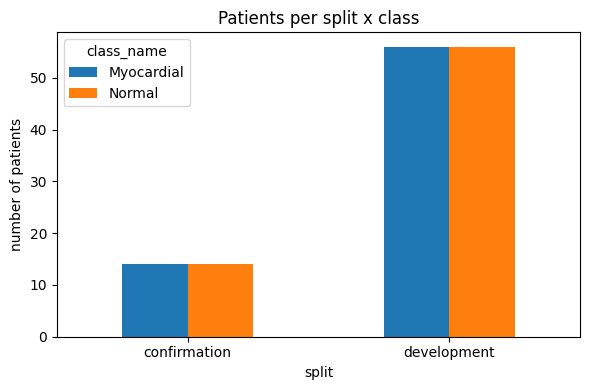

In [10]:
import matplotlib.pyplot as plt

summary = patient_split.groupby(["split", "class_name"])["patient_id"].count().unstack(fill_value=0)
ax = summary.plot(kind="bar", figsize=(6, 4), rot=0)
ax.set_ylabel("number of patients")
ax.set_title("Patients per split x class")
plt.tight_layout(); plt.show()

## 5. Save this stage's outputs

Everything downstream (Stage 2 onward) reads from `artifacts/01_split/`, never from
`config.DATA_DIR` directly — so the split assignment made here is guaranteed to be the one
every later stage uses.

In [11]:
patient_split.to_csv(STAGE_DIR / "patient_split.csv", index=False)
metadata_with_split.to_csv(STAGE_DIR / "metadata_with_split.csv", index=False)

config_used = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "data_dir": str(config.DATA_DIR),
    "seed": config.SEED,
    "confirmation_fraction": config.CONFIRMATION_FRACTION,
    "min_patients_per_class_for_split": config.MIN_PATIENTS_PER_CLASS_FOR_SPLIT,
    "n_recordings_total": int(len(metadata_with_split)),
    "n_patients_total": int(len(patient_split)),
    "patients_per_split_class": {
        f"{split}/{cls}": int(n)
        for (split, cls), n in patient_split.groupby(["split", "class_name"])["patient_id"].count().items()
    },
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2)

print("Saved:")
print(f"  {STAGE_DIR / 'patient_split.csv'}  ({len(patient_split)} patients)")
print(f"  {STAGE_DIR / 'metadata_with_split.csv'}  ({len(metadata_with_split)} recordings)")
print(f"  {STAGE_DIR / 'config_used.json'}")
print("\nConfirmation-set patients are now locked -- no later stage should read raw files for")
print("them outside of Stage 5's replication check.")

Saved:
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/01_split/patient_split.csv  (140 patients)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/01_split/metadata_with_split.csv  (3360 recordings)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/01_split/config_used.json

Confirmation-set patients are now locked -- no later stage should read raw files for
them outside of Stage 5's replication check.


## Next: Stage 2

Stage 2 reads `artifacts/01_split/metadata_with_split.csv`, computes phase boundaries
(S1/systole/S2/diastole) for every recording — starting with the simple heuristic segmenter,
CUED HSMM to follow — and saves those boundaries as this pipeline's next artifact. It only
ever touches `split == "development"` recordings; confirmation-set recordings are carried
through unsegmented until Stage 5.